# Exploratory Data Analysis and Data Quality: U.S. Residential Electricity Sales

**ADS 506 Final Project, Team 9**

Monthly U.S. residential electricity sales, EIA *Monthly Energy Review* Table 7.6 (series `ESRCPUS`), million kWh. This notebook checks the series only. ETS, TSLM, and ARIMA stay in their own files.


In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(fpp3)
  library(patchwork)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 150)

## 1. Load and check the file

One row per month. Set a monthly index, keep sales in million kWh, and confirm there is nothing to fix. No rows are dropped.


In [2]:
raw <- read.csv("data/residential_electricity.csv")

stopifnot(identical(names(raw), c("date", "residential_million_kwh")))
stopifnot(anyDuplicated(raw$date) == 0)
stopifnot(!anyNA(raw$residential_million_kwh))
stopifnot(all(raw$residential_million_kwh > 0))

sales <- raw |>
  mutate(Month = yearmonth(as.Date(date)), Sales = residential_million_kwh) |>
  select(Month, Sales) |>
  as_tsibble(index = Month)

stopifnot(nrow(sales) == 643)
stopifnot(min(sales$Month) == yearmonth("1973 Jan"))
stopifnot(max(sales$Month) == yearmonth("2026 Jul"))
stopifnot(isFALSE(has_gaps(sales)$.gaps))

quality <- tibble(
  Check = c(
    "Months",
    "First month",
    "Last month",
    "Missing sales values",
    "Duplicate months",
    "Missing months in the index",
    "Non-positive values"
  ),
  Result = c(
    as.character(nrow(sales)),
    format(min(sales$Month)),
    format(max(sales$Month)),
    as.character(sum(is.na(sales$Sales))),
    as.character(sum(duplicated(sales$Month))),
    "none",
    as.character(sum(sales$Sales <= 0))
  )
)

quality

Check,Result
<chr>,<chr>
Months,643
First month,1973 Jan
Last month,2026 Jul
Missing sales values,0
Duplicate months,0
Missing months in the index,none
Non-positive values,0


January 1973 through July 2026, 643 months. No gaps, no missing sales, and no non-positive values. May 1973 is the low and July 2026 is the high. Degree days are not in this file.


In [3]:
range_tbl <- sales |>
  filter(Sales == min(Sales) | Sales == max(Sales)) |>
  mutate(Sales = round(Sales))

range_tbl

Month,Sales
<mth>,<dbl>
1973 May,39825
2026 Jul,169666


## 2. Full history

Sales climb until about 2010 and then level off, which is why the models start in January 2010. The orange line is a 12-month average for seeing the level. It is not saved.


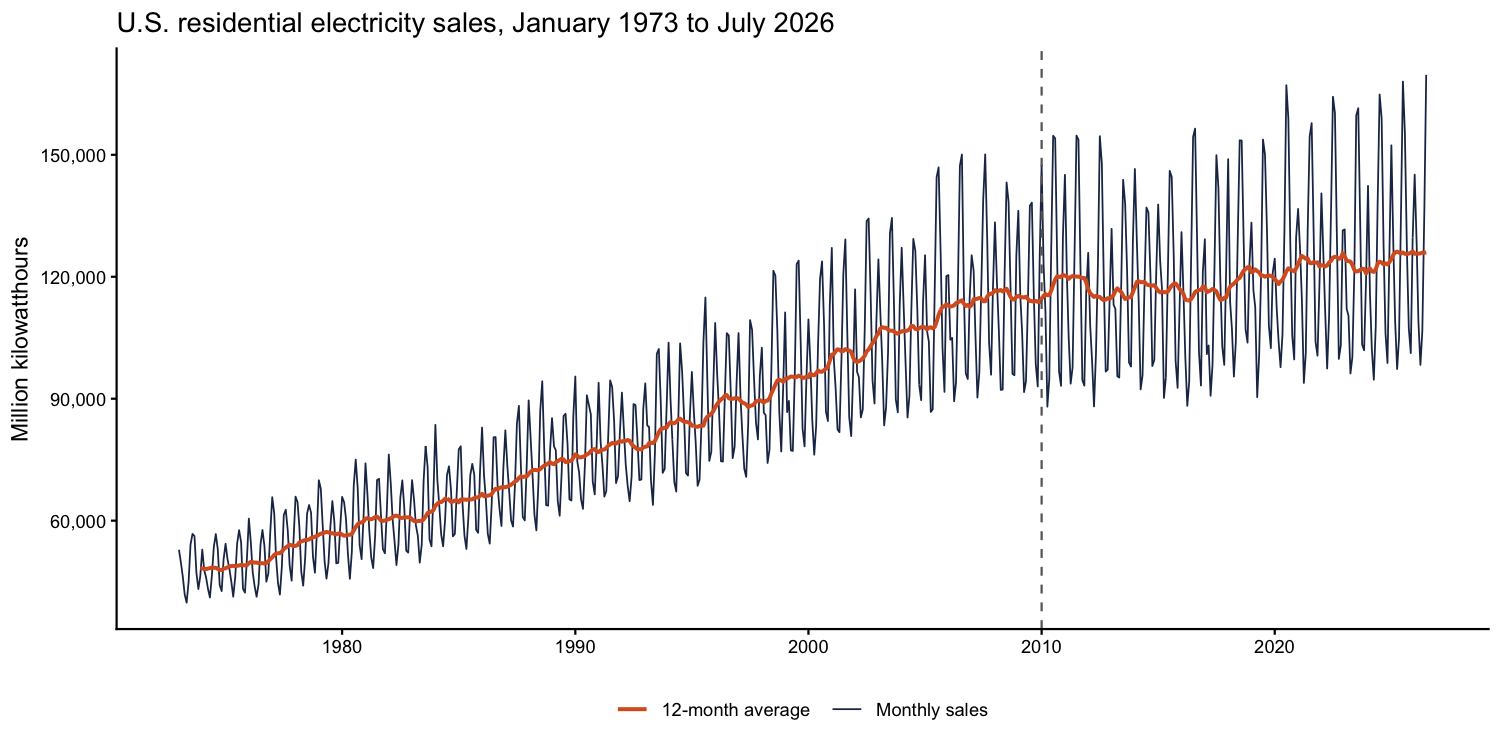

In [4]:
sales <- sales |>
  mutate(MA12 = slider::slide_dbl(Sales, mean, .before = 11, .complete = TRUE))

sales |>
  ggplot(aes(x = as.Date(Month))) +
  geom_line(aes(y = Sales, colour = "Monthly sales"), linewidth = 0.4) +
  geom_line(
    data = \(df) filter(df, !is.na(MA12)),
    aes(y = MA12, colour = "12-month average"),
    linewidth = 0.9
  ) +
  geom_vline(xintercept = as.Date("2010-01-01"), linetype = "dashed", colour = "grey40") +
  scale_colour_manual(values = c("Monthly sales" = "#1F3354", "12-month average" = "#D95F27")) +
  scale_y_continuous(labels = scales::comma) +
  labs(
    title = "U.S. residential electricity sales, January 1973 to July 2026",
    x = NULL, y = "Million kilowatthours", colour = NULL
  ) +
  theme_classic() +
  theme(legend.position = "bottom")

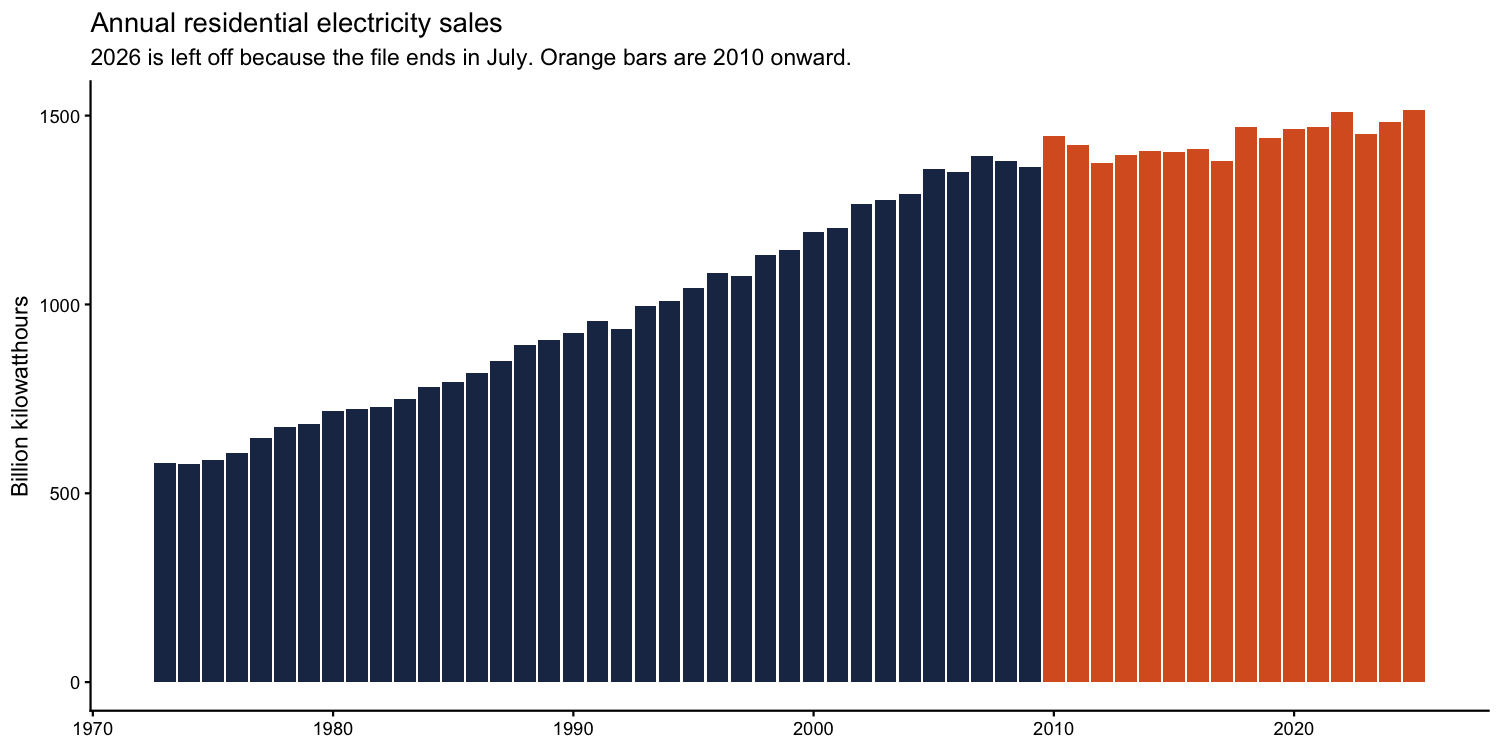

In [5]:
annual <- sales |>
  index_by(Year = ~ year(.)) |>
  summarise(
    Months = n(),
    `Billion kWh` = round(sum(Sales) / 1000, 1)
  ) |>
  filter(Months == 12)

annual |>
  ggplot(aes(x = Year, y = `Billion kWh`, fill = Year >= 2010)) +
  geom_col() +
  scale_fill_manual(values = c("TRUE" = "#D95F27", "FALSE" = "#1F3354"), guide = "none") +
  labs(
    title = "Annual residential electricity sales",
    subtitle = "2026 is left off because the file ends in July. Orange bars are 2010 onward.",
    x = NULL, y = "Billion kilowatthours"
  ) +
  theme_classic()

In [6]:
# Complete years only, so 2026 does not look like a drop
picked <- annual |>
  as_tibble() |>
  filter(Year %in% c(1973, 2000, 2010, 2019, 2020, 2025)) |>
  select(Year, `Billion kWh`)

picked

value <- function(year) picked$`Billion kWh`[picked$Year == year]
tibble(
  Comparison = c("1973 to 2010", "2000 to 2010", "2010 to 2025", "2019 to 2020"),
  Percent_change = round(100 * c(
    value(2010) / value(1973) - 1,
    value(2010) / value(2000) - 1,
    value(2025) / value(2010) - 1,
    value(2020) / value(2019) - 1
  ), 1)
)

Year,Billion kWh
<dbl>,<dbl>
1973,579.2
2000,1192.4
2010,1445.7
2019,1440.3
2020,1464.6
2025,1515.0


Comparison,Percent_change
<chr>,<dbl>
1973 to 2010,149.6
2000 to 2010,21.2
2010 to 2025,4.8
2019 to 2020,1.7


Trend strength is about 0.98 on the full series and about 0.44 from 2010 on. Seasonality stays strong in both periods, with a July peak and an April trough.


In [7]:
bind_rows(
  sales |> features(Sales, feat_stl) |> mutate(Series = "1973 to 2026"),
  sales |> filter_index("2010 Jan" ~ "2026 Jul") |>
    features(Sales, feat_stl) |> mutate(Series = "2010 to 2026")
) |>
  select(Series, trend_strength, seasonal_strength_year, seasonal_peak_year, seasonal_trough_year) |>
  mutate(across(where(is.numeric), \(x) round(x, 3)))

Series,trend_strength,seasonal_strength_year,seasonal_peak_year,seasonal_trough_year
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1973 to 2026,0.983,0.952,7,4
2010 to 2026,0.439,0.955,7,4


## 3. Modeling window

January 2010 through July 2026. Training ends in July 2025. The last 12 months are the holdout. No forecast is scored here.


In [8]:
window <- sales |>
  select(Month, Sales) |>
  filter_index("2010 Jan" ~ "2026 Jul")

train <- window |> filter_index(~ "2025 Jul")
test  <- window |> filter_index("2025 Aug" ~ .)

stopifnot(nrow(window) == 199)
stopifnot(nrow(train) == 187)
stopifnot(nrow(test) == 12)
stopifnot(max(train$Month) == yearmonth("2025 Jul"))
stopifnot(min(test$Month) == yearmonth("2025 Aug"))
stopifnot(max(test$Month) == yearmonth("2026 Jul"))

cat(
  "Window:", format(min(window$Month)), "to", format(max(window$Month)),
  "(", nrow(window), "months )\n"
)
cat(
  "Train: ", format(min(train$Month)), "to", format(max(train$Month)),
  "(", nrow(train), "months )\n"
)
cat(
  "Test:  ", format(min(test$Month)), "to", format(max(test$Month)),
  "(", nrow(test), "months )\n"
)

Window: 2010 Jan to 2026 Jul ( 199 months )


Train:  2010 Jan to 2025 Jul ( 187 months )


Test:   2025 Aug to 2026 Jul ( 12 months )


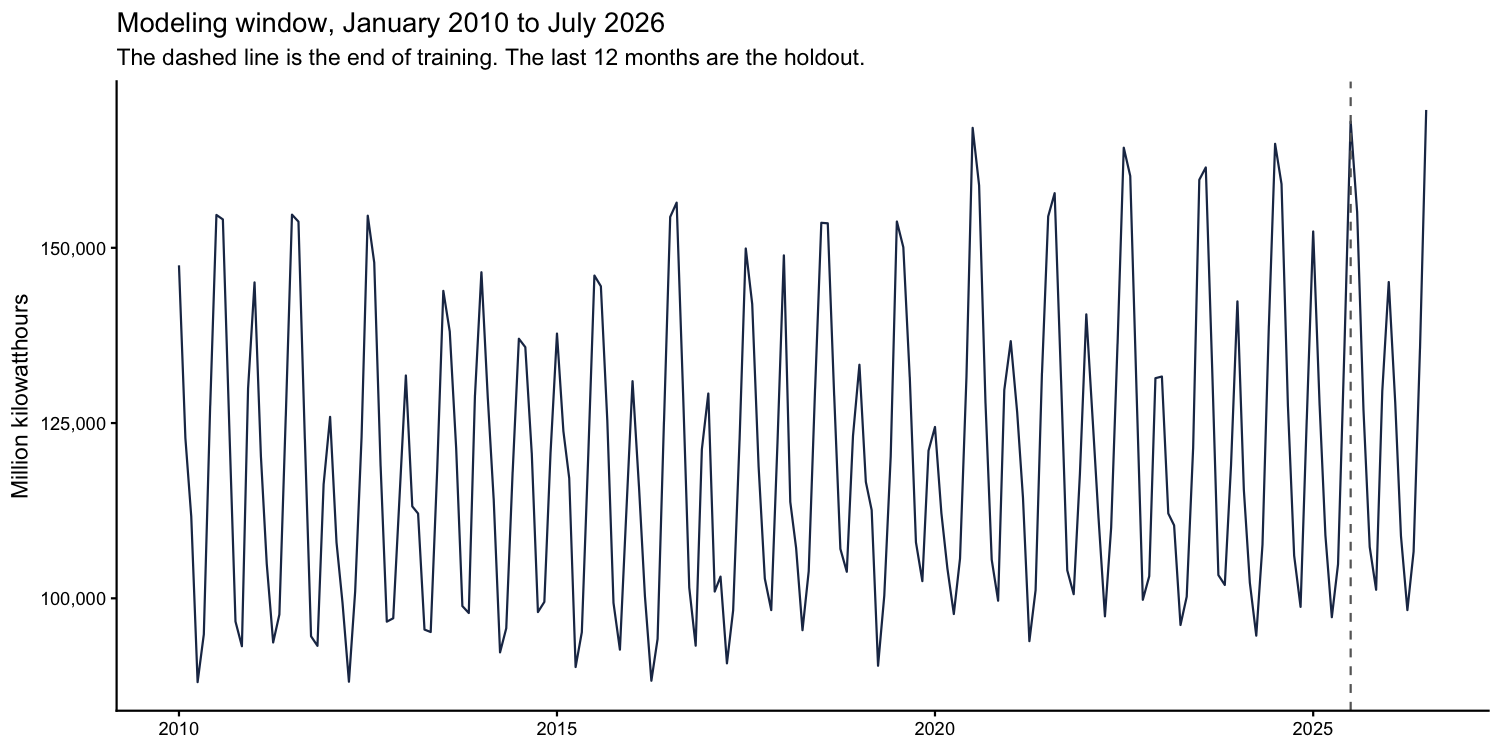

In [9]:
window |>
  ggplot(aes(x = as.Date(Month), y = Sales)) +
  geom_line(colour = "#1F3354", linewidth = 0.5) +
  geom_vline(xintercept = as.Date("2025-07-01"), linetype = "dashed", colour = "grey40") +
  scale_y_continuous(labels = scales::comma) +
  labs(
    title = "Modeling window, January 2010 to July 2026",
    subtitle = "The dashed line is the end of training. The last 12 months are the holdout.",
    x = NULL, y = "Million kilowatthours"
  ) +
  theme_classic()

## 4. Seasonality

A high summer, a smaller winter peak, and a low spring. On 2010–2024, July is about 29% above a typical month, January about 14% above, and April about 22% below.


In [10]:
complete <- window |> filter_index("2010 Jan" ~ "2024 Dec")

month_profile <- complete |>
  as_tibble() |>
  mutate(MonthName = month(Month, label = TRUE, abbr = TRUE)) |>
  group_by(MonthName) |>
  summarise(Average = mean(Sales), .groups = "drop") |>
  mutate(
    Percent_vs_typical_month = round(100 * (Average / mean(complete$Sales) - 1), 1),
    Versus_April = round(Average / Average[MonthName == "Apr"], 2),
    Average = round(Average)
  )

month_profile

MonthName,Average,Percent_vs_typical_month,Versus_April
<ord>,<dbl>,<dbl>,<dbl>
Jan,136836,14.4,1.47
Feb,117016,-2.1,1.26
Mar,108360,-9.4,1.17
Apr,92843,-22.4,1.00
May,100061,-16.3,1.08
Jun,126051,5.4,1.36
Jul,154198,28.9,1.66
Aug,151582,26.8,1.63
Sep,126044,5.4,1.36


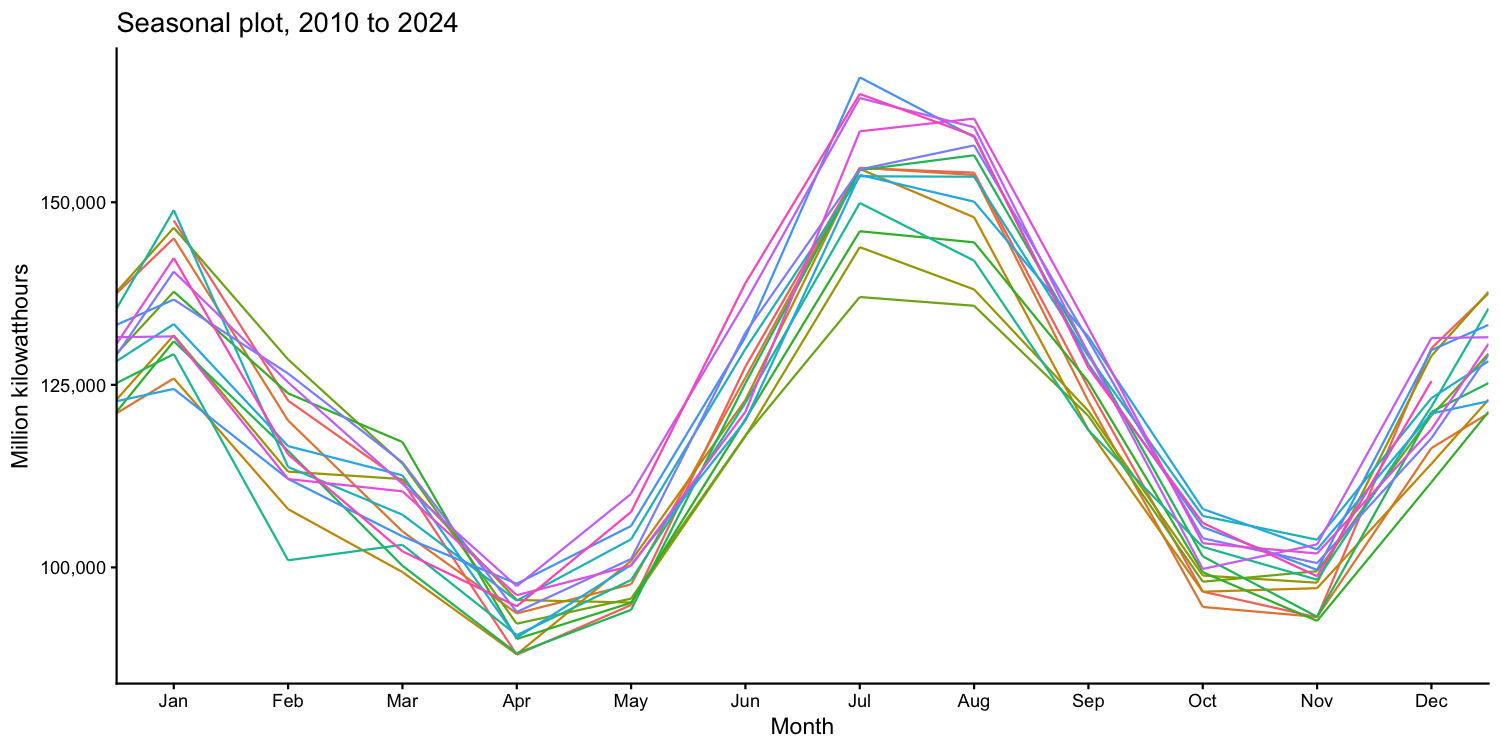

In [11]:
complete |>
  gg_season(Sales, labels = "none") +
  scale_y_continuous(labels = scales::comma) +
  labs(
    title = "Seasonal plot, 2010 to 2024",
    y = "Million kilowatthours"
  ) +
  theme_classic() +
  theme(legend.position = "none")

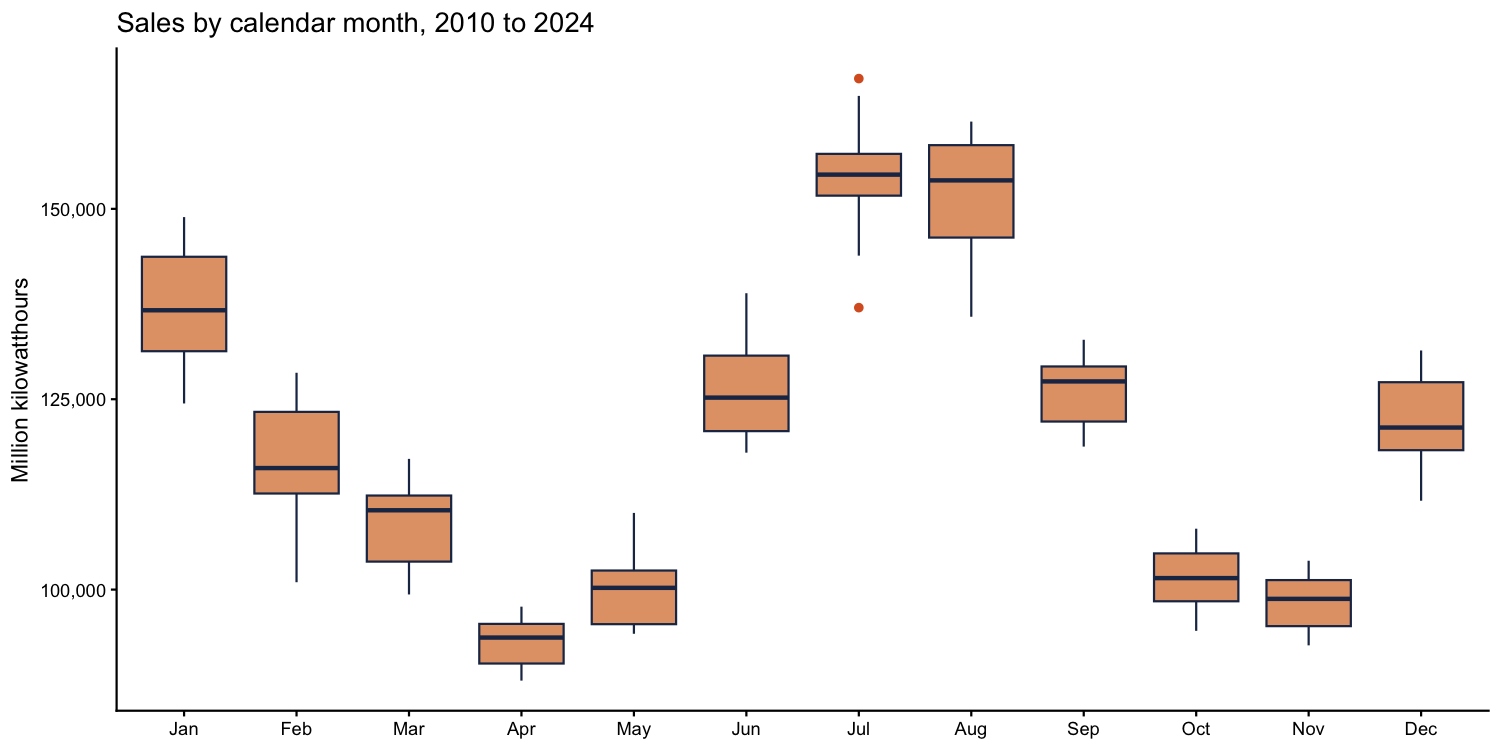

In [12]:
complete |>
  ggplot(aes(x = month(Month, label = TRUE, abbr = TRUE), y = Sales)) +
  geom_boxplot(fill = "#E3A277", colour = "#1F3354", outlier.colour = "#D95F27") +
  scale_y_continuous(labels = scales::comma) +
  labs(
    title = "Sales by calendar month, 2010 to 2024",
    x = NULL, y = "Million kilowatthours"
  ) +
  theme_classic()

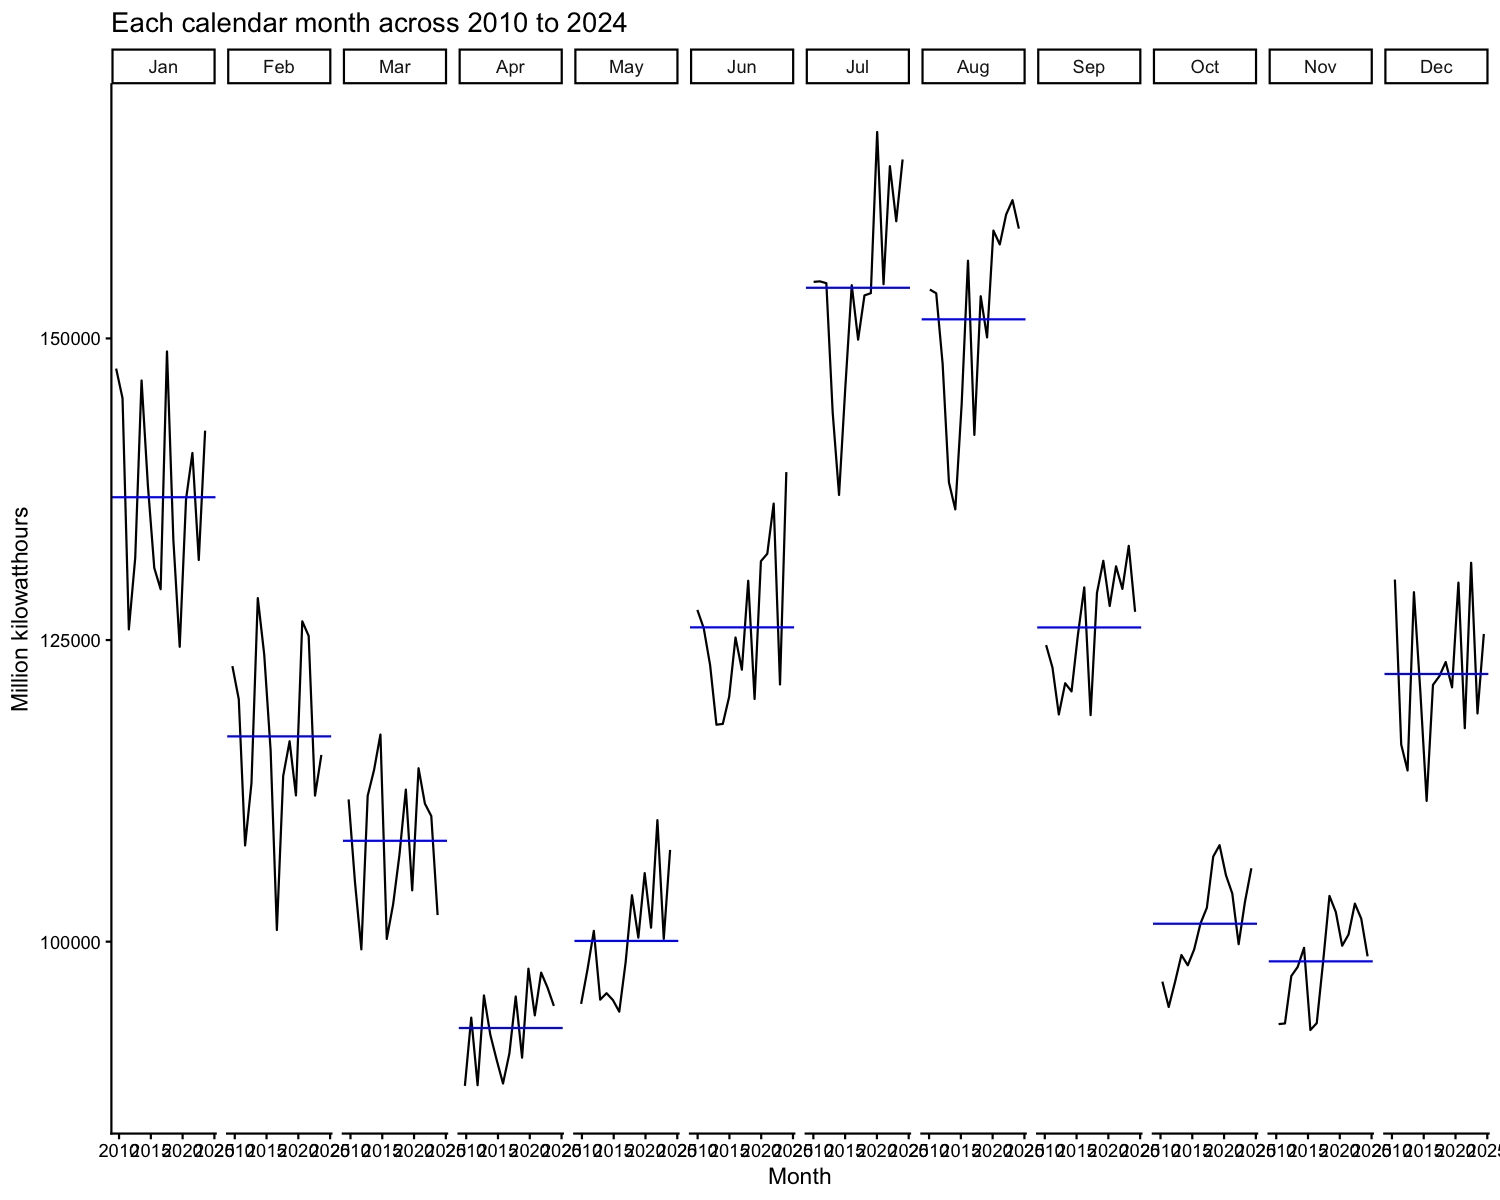

In [13]:
options(repr.plot.height = 8)

complete |>
  gg_subseries(Sales) +
  labs(
    title = "Each calendar month across 2010 to 2024",
    y = "Million kilowatthours"
  ) +
  theme_classic()

options(repr.plot.height = 5)

## 5. Data quality

No imputation. The largest leftovers from a seasonal-trend split are real months, and they stay in the series. 2020 is higher after March, not in every month. The latest EIA months, including July 2026, are preliminary.


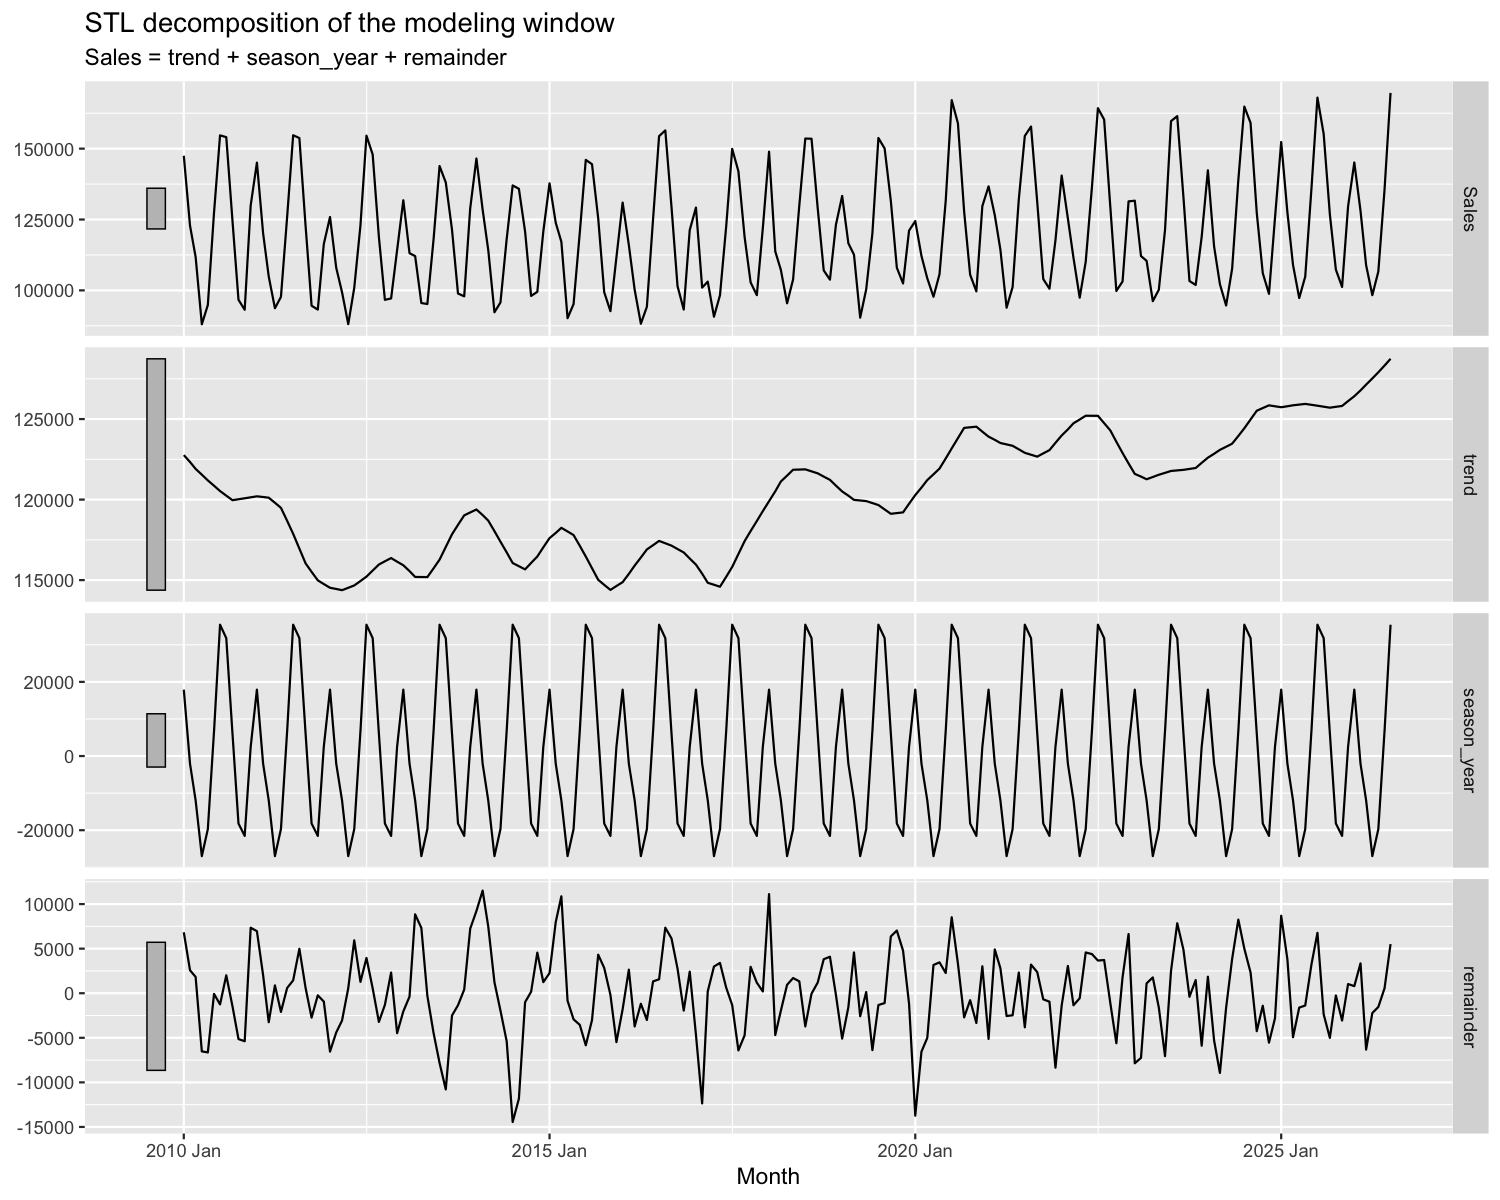

In [14]:
options(repr.plot.height = 8)

components <- window |>
  model(STL(Sales ~ season(window = "periodic"))) |>
  components()

components |>
  autoplot() +
  labs(title = "STL decomposition of the modeling window")

options(repr.plot.height = 5)

In [15]:
remainders <- components |>
  as_tibble() |>
  mutate(z = remainder / sd(remainder, na.rm = TRUE)) |>
  filter(abs(z) >= 2.5) |>
  arrange(desc(abs(z))) |>
  transmute(
    Month,
    Sales = round(Sales),
    Remainder = round(remainder),
    Standard_deviations = round(z, 2)
  )

remainders

Month,Sales,Remainder,Standard_deviations
<mth>,<dbl>,<dbl>,<dbl>
2014 Jul,137028,-14445,-3.07
2020 Jan,124442,-13738,-2.92
2017 Feb,100968,-12359,-2.63
2014 Aug,135830,-11833,-2.52


In [16]:
same_month <- window |>
  as_tibble() |>
  mutate(Calendar_month = month(Month)) |>
  group_by(Calendar_month) |>
  mutate(z = (Sales - mean(Sales)) / sd(Sales)) |>
  ungroup()

cat("Largest same-month departure, in standard deviations:", round(max(abs(same_month$z)), 2), "\n")

Largest same-month departure, in standard deviations: 2.19 


In [17]:
yoy_2020 <- window |>
  filter_index("2019 Jan" ~ "2020 Dec") |>
  as_tibble() |>
  mutate(Year = year(Month), MonthName = month(Month, label = TRUE, abbr = TRUE)) |>
  select(Year, MonthName, Sales) |>
  pivot_wider(names_from = Year, values_from = Sales) |>
  mutate(
    Difference = round(`2020` - `2019`),
    Percent = round(100 * (`2020` / `2019` - 1), 1),
    `2019` = round(`2019`),
    `2020` = round(`2020`)
  )

yoy_2020

MonthName,2019,2020,Difference,Percent
<ord>,<dbl>,<dbl>,<dbl>,<dbl>
Jan,133318,124442,-8875,-6.7
Feb,116608,112123,-4485,-3.8
Mar,112605,104255,-8350,-7.4
Apr,90384,97759,7375,8.2
May,100331,105681,5350,5.3
Jun,120116,131538,11422,9.5
Jul,153749,167108,13359,8.7
Aug,150083,158939,8856,5.9
Sep,131567,127824,-3743,-2.8


## 6. Smoothing, differencing, and transformation

None of the three is applied to the saved series. The 12-month average is only a viewing aid. A 12-month difference is a candidate inside ARIMA, not a new column. A log was checked, and the original million-kWh units were kept.


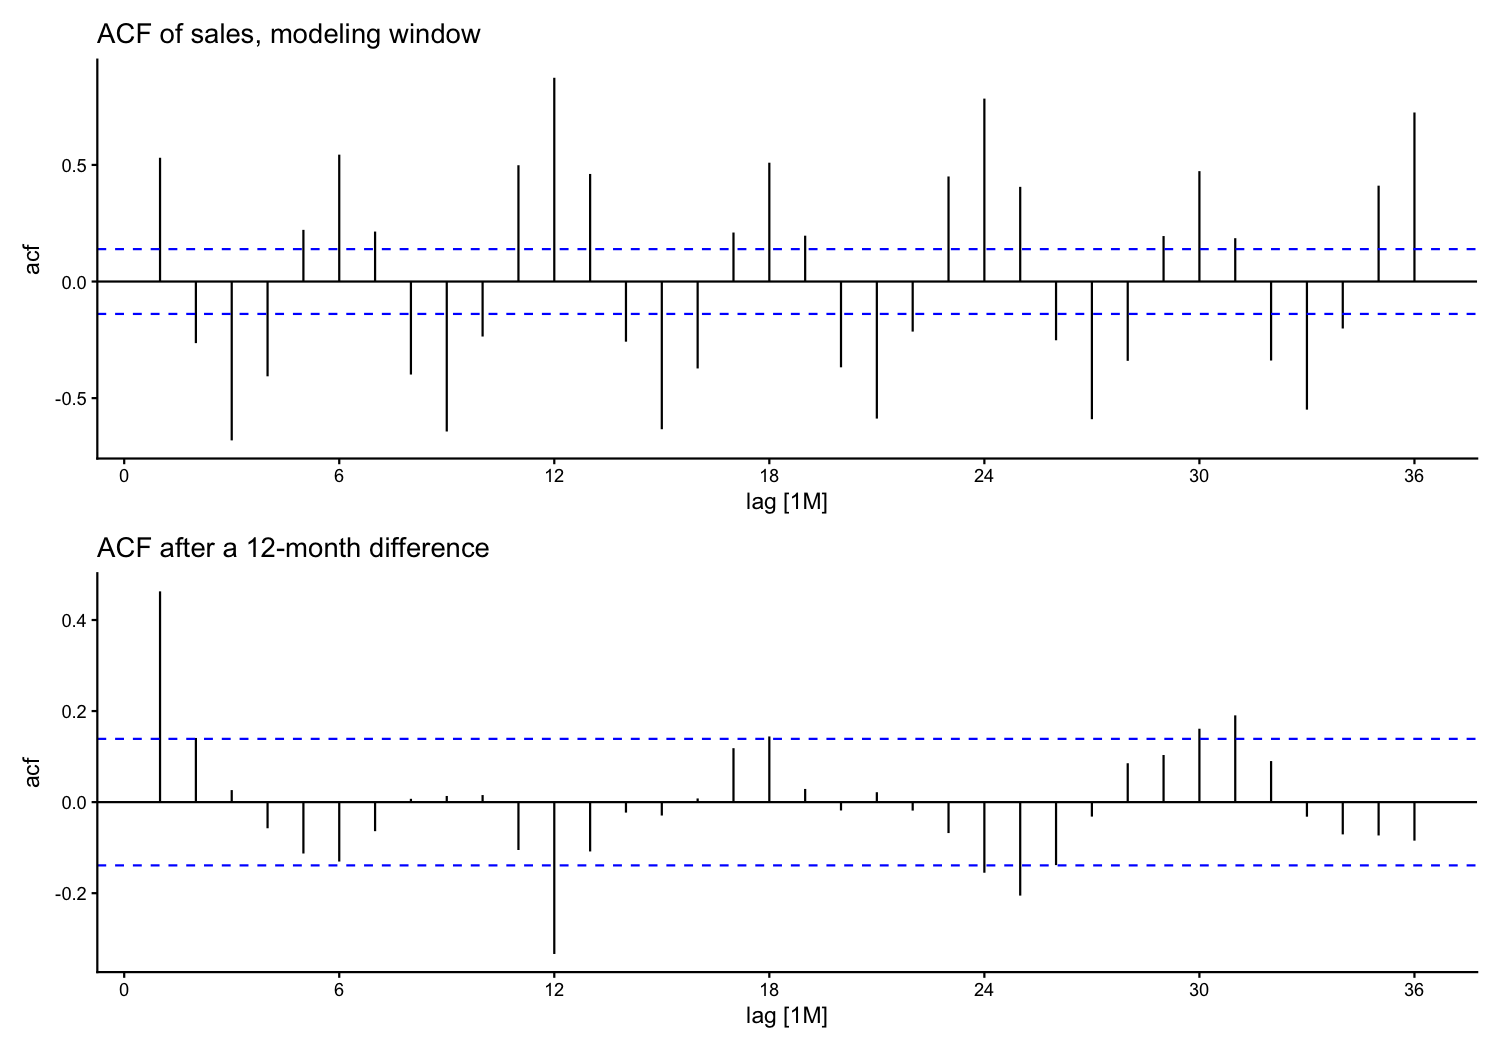

In [18]:
options(repr.plot.height = 7)

p_level <- window |>
  ACF(Sales, lag_max = 36) |>
  autoplot() +
  labs(title = "ACF of sales, modeling window") +
  theme_classic()

p_diff <- window |>
  ACF(difference(Sales, 12), lag_max = 36) |>
  autoplot() +
  labs(title = "ACF after a 12-month difference") +
  theme_classic()

p_level / p_diff

options(repr.plot.height = 5)

In [19]:
# Peak-to-trough ratio of the average month, by decade. 2026 is left out.
sales |>
  filter_index(~ "2025 Dec") |>
  as_tibble() |>
  mutate(Decade = (year(Month) %/% 10) * 10, Calendar_month = month(Month)) |>
  group_by(Decade, Calendar_month) |>
  summarise(Average = mean(Sales), .groups = "drop") |>
  group_by(Decade) |>
  summarise(
    Peak_over_trough = round(max(Average) / min(Average), 2),
    .groups = "drop"
  )

Decade,Peak_over_trough
<dbl>,<dbl>
1970,1.43
1980,1.49
1990,1.50
2000,1.59
2010,1.65
2020,1.69


## 7. Shared series for the model notebooks

Each model file reads the CSV on its own: million kWh, January 2010–July 2026, train through July 2025, test August 2025–July 2026.


In [20]:
# The load the model notebooks repeat. No model is fit here.
model_sales <- read.csv("data/residential_electricity.csv") |>
  mutate(Month = yearmonth(as.Date(date)), Sales = residential_million_kwh) |>
  select(Month, Sales) |>
  as_tsibble(index = Month) |>
  filter_index("2010 Jan" ~ "2026 Jul")

model_train <- model_sales |> filter_index(~ "2025 Jul")
model_test  <- model_sales |> filter_index("2025 Aug" ~ .)

cat(nrow(model_train), "training months,", nrow(model_test), "test months\n")

187 training months, 12 test months


## References

U.S. Energy Information Administration. (2026). *Monthly Energy Review, Table 7.6: Electricity end use* [Data set]. https://www.eia.gov/totalenergy/data/browser/?tbl=T07.06
